In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "không có")

if not torch.cuda.is_available():
    raise RuntimeError("Hãy đổi runtime sang GPU rồi chạy lại.")

PyTorch: 2.11.0+cu130
GPU: Tesla T4


In [ ]:
import torch
import pyarrow
import datasets
import transformers

print("GPU:", torch.cuda.is_available())
print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)

GPU: True
PyArrow: 25.0.1
Datasets: 5.1.0
Transformers: 5.19.0


In [ ]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion", "split")
print({split: len(rows) for split, rows in dataset.items()})
print(dataset["train"].features["label"].names)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

{'train': 16000, 'validation': 2000, 'test': 2000}
['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [ ]:
from transformers import AutoTokenizer

MODEL_ID = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

tokenized = dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"],
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)

id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
    }

args = TrainingArguments(
    output_dir="/content/emo-checkpoints",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.242443,0.197536,0.928500,0.901309
2,0.145299,0.151433,0.936000,0.910285
3,0.098820,0.140157,0.947000,0.926842


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3000, training_loss=0.2414893633524577, metrics={'train_runtime': 178.0079, 'train_samples_per_second': 269.651, 'train_steps_per_second': 16.853, 'total_flos': 584777647046016.0, 'train_loss': 0.2414893633524577, 'epoch': 3.0})

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

model_dir = Path("/content/drive/MyDrive/emo/distilbert-emotion")
model_dir.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(model_dir))
tokenizer.save_pretrained(str(model_dir))

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/emo/distilbert-emotion/tokenizer_config.json',
 '/content/drive/MyDrive/emo/distilbert-emotion/tokenizer.json')

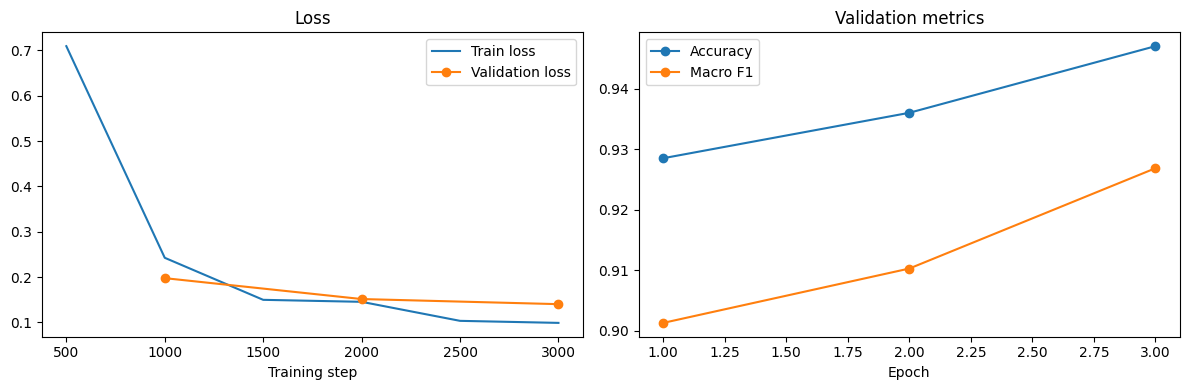

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_logs = [x for x in history if "loss" in x and "eval_loss" not in x]
eval_logs = [x for x in history if "eval_loss" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot([x["step"] for x in train_logs], [x["loss"] for x in train_logs],
             label="Train loss")
axes[0].plot([x["step"] for x in eval_logs], [x["eval_loss"] for x in eval_logs],
             marker="o", label="Validation loss")
axes[0].set(title="Loss", xlabel="Training step")
axes[0].legend()

for key, name in [("eval_accuracy", "Accuracy"), ("eval_macro_f1", "Macro F1")]:
    axes[1].plot([x["epoch"] for x in eval_logs], [x[key] for x in eval_logs],
                 marker="o", label=name)
axes[1].set(title="Validation metrics", xlabel="Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

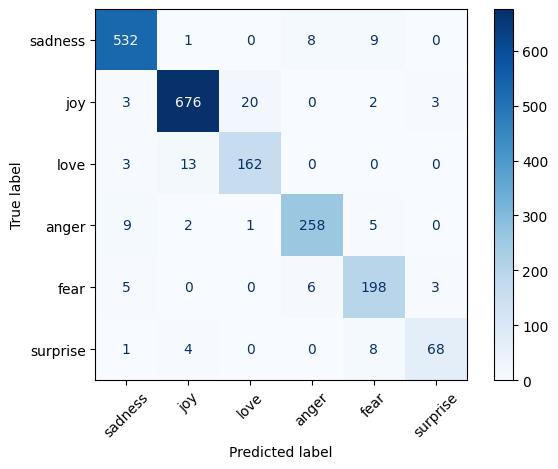

In [ ]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

pred = trainer.predict(tokenized["validation"])
y_true = pred.label_ids
y_pred = np.argmax(pred.predictions, axis=-1)

cm = confusion_matrix(y_true, y_pred, labels=range(len(label_names)))
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(
    cmap="Blues", values_format="d", xticks_rotation=45
)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

MODEL_DIR = "/content/drive/MyDrive/emo/distilbert-emotion"

# trainer đang giữ best model nhờ load_best_model_at_end=True
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Đã lưu model và tokenizer tại:", MODEL_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu model và tokenizer tại: /content/drive/MyDrive/emo/distilbert-emotion


In [ ]:
%pip -q install datasets transformers accelerate scikit-learn matplotlib "pyarrow>=19,<24"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 20.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from datasets import load_dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)
from collections import Counter
import numpy as np
import torch

MODEL_DIR = "/content/drive/MyDrive/emo/distilbert-emotion"

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)

id2label = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
label2id = {name: idx for idx, name in id2label.items()}
target_labels = {"sadness", "joy", "love", "anger", "fear", "surprise"}

assert target_labels.issubset(label2id), (
    f"Nhãn trong checkpoint không khớp: {id2label}"
)

go_test = load_dataset(
    "google-research-datasets/go_emotions",
    "simplified",
    split="test",
)

go_label_names = go_test.features["labels"].feature.names

# Giữ một nhãn duy nhất thuộc sáu nhãn của model
go_test = go_test.filter(
    lambda row: (
        len(row["labels"]) == 1
        and go_label_names[row["labels"][0]] in target_labels
    )
)

def add_model_label(row):
    name = go_label_names[row["labels"][0]]
    return {"gold_label": name, "label": label2id[name]}

go_test = go_test.map(add_model_label)

print("Số mẫu sau lọc:", len(go_test))
print("Phân bố nhãn:", dict(Counter(go_test["gold_label"])))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5427 [00:00<?, ? examples/s]

Map:   0%|          | 0/638 [00:00<?, ? examples/s]

Số mẫu sau lọc: 638
Phân bố nhãn: {'sadness': 102, 'fear': 65, 'love': 160, 'surprise': 87, 'anger': 131, 'joy': 93}


Map:   0%|          | 0/638 [00:00<?, ? examples/s]

GoEmotions test samples: 638
Accuracy: 0.5000
Macro F1: 0.4737

              precision    recall  f1-score   support

     sadness     0.6176    0.6176    0.6176       102
         joy     0.3575    0.7957    0.4933        93
        love     0.8667    0.1625    0.2737       160
       anger     0.4904    0.7786    0.6018       131
        fear     0.5571    0.6000    0.5778        65
    surprise     0.7143    0.1724    0.2778        87

    accuracy                         0.5000       638
   macro avg     0.6006    0.5211    0.4737       638
weighted avg     0.6231    0.5000    0.4596       638



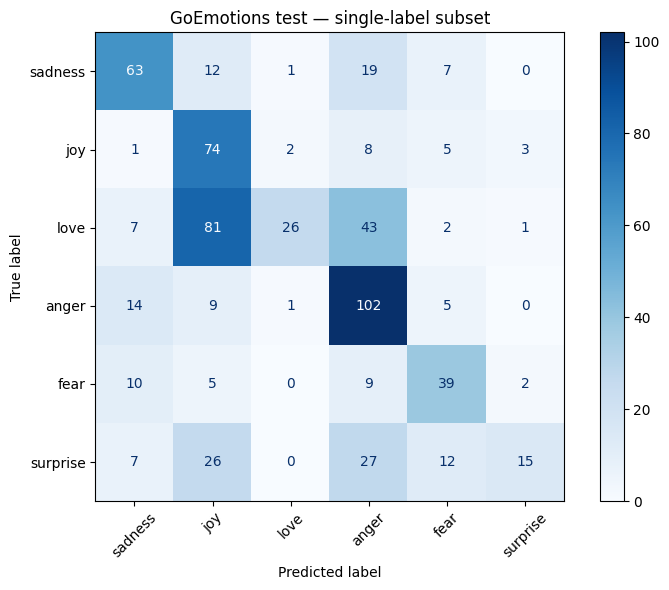

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import os
import json

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128,  # cùng max_length đã dùng khi train
    )

columns_to_remove = [c for c in go_test.column_names if c != "label"]
tokenized_test = go_test.map(
    tokenize_batch,
    batched=True,
    remove_columns=columns_to_remove,
)

eval_args = TrainingArguments(
    output_dir="/content/go-emotions-eval",
    per_device_eval_batch_size=32,
    report_to="none",
)

eval_trainer = Trainer(
    model=model,
    args=eval_args,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
)

output = eval_trainer.predict(tokenized_test)
y_true = output.label_ids
y_pred = np.argmax(output.predictions, axis=-1)

label_ids = list(range(model.config.num_labels))
label_names = [id2label[i] for i in label_ids]

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"GoEmotions test samples: {len(y_true)}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print()
print(classification_report(
    y_true,
    y_pred,
    labels=label_ids,
    target_names=label_names,
    digits=4,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=label_ids,
    display_labels=label_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)
plt.title("GoEmotions test — single-label subset")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

MODEL_DIR = "/content/drive/MyDrive/emo/distilbert-emotion"

trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
print("Đã lưu checkpoint:", MODEL_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu checkpoint: /content/drive/MyDrive/emo/distilbert-emotion


In [ ]:
from datasets import Value, concatenate_datasets
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)
import torch
import numpy as np

# Đồng bộ kiểu dữ liệu cột label trước khi nối
dair_train_tok = dair_train_tok.cast_column("label", Value("int64"))
go_train_tok = go_train_tok.cast_column("label", Value("int64"))
dair_valid_tok = dair_valid_tok.cast_column("label", Value("int64"))
go_valid_tok = go_valid_tok.cast_column("label", Value("int64"))

mixed_train = concatenate_datasets([dair_train_tok, go_train_tok])
mixed_valid = concatenate_datasets([dair_valid_tok, go_valid_tok])

print("DAIR.AI train:", len(dair_train_tok))
print("GoEmotions train sau lọc:", len(go_train_tok))
print("Tổng câu train:", len(mixed_train))
print("Validation gộp:", len(mixed_valid))

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
    }

set_seed(42)

args = TrainingArguments(
    output_dir="/content/emo-mixed-checkpoints",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=mixed_train,
    eval_dataset=mixed_valid,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

Casting the dataset:   0%|          | 0/16000 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/5272 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/625 [00:00<?, ? examples/s]

DAIR.AI train: 16000
GoEmotions train sau lọc: 5272
Tổng câu train: 21272
Validation gộp: 2625


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.222839,0.219158,0.926857,0.909002
2,0.145487,0.212673,0.929905,0.914566


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2660, training_loss=0.19288455059653833, metrics={'train_runtime': 176.7434, 'train_samples_per_second': 240.711, 'train_steps_per_second': 15.05, 'total_flos': 494509164702048.0, 'train_loss': 0.19288455059653833, 'epoch': 2.0})

In [ ]:
# trainer đã nạp best checkpoint sau khi train xong
trainer.save_model(NEW_MODEL_DIR)
tokenizer.save_pretrained(NEW_MODEL_DIR)
print("Đã lưu:", NEW_MODEL_DIR)

print("DAIR.AI validation:")
print(trainer.evaluate(dair_valid_tok, metric_key_prefix="dair_val"))

print("GoEmotions validation:")
print(trainer.evaluate(go_valid_tok, metric_key_prefix="go_val"))

# Đánh giá cuối trên GoEmotions test, vẫn lọc theo cùng quy tắc sáu nhãn đơn
from datasets import Value

go_test = load_go_split("test")
go_test_tok = tokenize_dataset(go_test)
go_test_tok = go_test_tok.cast_column("label", Value("int64"))

print("GoEmotions test:")
print(trainer.evaluate(go_test_tok, metric_key_prefix="go_test"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu: /content/drive/MyDrive/emo/distilbert-emotion-mixed-v1
DAIR.AI validation:


Training Loss,Validation Loss,Epoch,Val Loss,Val Accuracy,Val Macro F1
0.145487,No log,2,0.144325,0.945500,0.921606


{'dair_val_loss': 0.1443251073360443, 'dair_val_accuracy': 0.9455, 'dair_val_macro_f1': 0.9216062603930727}
GoEmotions validation:


Training Loss,Validation Loss,Epoch,Val Loss,Val Accuracy,Val Macro F1
0.145487,No log,2,0.431387,0.880000,0.868798


...

Map:   0%|          | 0/638 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/638 [00:00<?, ? examples/s]

GoEmotions test:


Training Loss,Validation Loss,Epoch,Test Loss,Test Accuracy,Test Macro F1
0.145487,No log,2,0.628800,0.835423,0.819907


{'go_test_loss': 0.6287996768951416, 'go_test_accuracy': 0.835423197492163, 'go_test_macro_f1': 0.8199066855182607}


Map:   0%|          | 0/638 [00:00<?, ? examples/s]

GoEmotions test samples: 638
Accuracy: 0.8354
Macro F1: 0.8199

              precision    recall  f1-score   support

     sadness     0.8039    0.8039    0.8039       102
         joy     0.8021    0.8280    0.8148        93
        love     0.9490    0.9313    0.9401       160
       anger     0.8438    0.8244    0.8340       131
        fear     0.7361    0.8154    0.7737        65
    surprise     0.7711    0.7356    0.7529        87

    accuracy                         0.8354       638
   macro avg     0.8177    0.8231    0.8199       638
weighted avg     0.8368    0.8354    0.8358       638



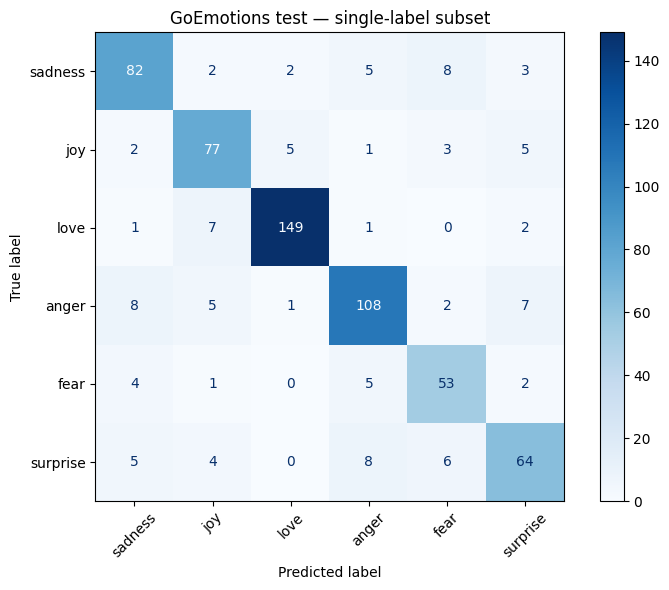

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import os
import json

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128,  # cùng max_length đã dùng khi train
    )

columns_to_remove = [c for c in go_test.column_names if c != "label"]
tokenized_test = go_test.map(
    tokenize_batch,
    batched=True,
    remove_columns=columns_to_remove,
)

eval_args = TrainingArguments(
    output_dir="/content/go-emotions-eval",
    per_device_eval_batch_size=32,
    report_to="none",
)

eval_trainer = Trainer(
    model=model,
    args=eval_args,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
)

output = eval_trainer.predict(tokenized_test)
y_true = output.label_ids
y_pred = np.argmax(output.predictions, axis=-1)

label_ids = list(range(model.config.num_labels))
label_names = [id2label[i] for i in label_ids]

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"GoEmotions test samples: {len(y_true)}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print()
print(classification_report(
    y_true,
    y_pred,
    labels=label_ids,
    target_names=label_names,
    digits=4,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=label_ids,
    display_labels=label_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)
plt.title("GoEmotions test — single-label subset")
plt.tight_layout()
plt.show()